In [1]:
import pandas as pd

df = pd.read_csv("../data/olist_orders_dataset.csv")

In [2]:
df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [3]:
df.shape

(99441, 8)

In [4]:
df.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date'],
      dtype='str')

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   order_id                       99441 non-null  str  
 1   customer_id                    99441 non-null  str  
 2   order_status                   99441 non-null  str  
 3   order_purchase_timestamp       99441 non-null  str  
 4   order_approved_at              99281 non-null  str  
 5   order_delivered_carrier_date   97658 non-null  str  
 6   order_delivered_customer_date  96476 non-null  str  
 7   order_estimated_delivery_date  99441 non-null  str  
dtypes: str(8)
memory usage: 6.1 MB


In [6]:
df['order_status'].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [7]:
df['order_id'].nunique()

99441

In [8]:
df['order_purchase_timestamp'] = pd.to_datetime(df['order_purchase_timestamp'])
df['order_purchase_timestamp'].dtype

dtype('<M8[us]')

In [9]:
date_columns = [
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date'
]

for col in date_columns:
    df[col] = pd.to_datetime(df[col])

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   order_id                       99441 non-null  str           
 1   customer_id                    99441 non-null  str           
 2   order_status                   99441 non-null  str           
 3   order_purchase_timestamp       99441 non-null  datetime64[us]
 4   order_approved_at              99281 non-null  datetime64[us]
 5   order_delivered_carrier_date   97658 non-null  datetime64[us]
 6   order_delivered_customer_date  96476 non-null  datetime64[us]
 7   order_estimated_delivery_date  99441 non-null  datetime64[us]
dtypes: datetime64[us](5), str(3)
memory usage: 6.1 MB


In [11]:
df.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [12]:
(df.isnull().sum() / len(df)) * 100

order_id                         0.000000
customer_id                      0.000000
order_status                     0.000000
order_purchase_timestamp         0.000000
order_approved_at                0.160899
order_delivered_carrier_date     1.793023
order_delivered_customer_date    2.981668
order_estimated_delivery_date    0.000000
dtype: float64

In [13]:
df.groupby('order_status')['order_delivered_customer_date'].apply(lambda x:x.isnull().sum())

order_status
approved          2
canceled        619
created           5
delivered         8
invoiced        314
processing      301
shipped        1107
unavailable     609
Name: order_delivered_customer_date, dtype: int64

In [14]:
df[
    (df['order_status'] == 'delivered') &
    (df['order_delivered_customer_date'].isnull())
]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,ec05a6d8558c6455f0cbbd8a420ad34f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaT,2017-12-18
20618,f5dd62b788049ad9fc0526e3ad11a097,5e89028e024b381dc84a13a3570decb4,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaT,2018-07-16
43834,2ebdfc4f15f23b91474edf87475f108e,29f0540231702fda0cfdee0a310f11aa,delivered,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaT,2018-07-30
79263,e69f75a717d64fc5ecdfae42b2e8e086,cfda40ca8dd0a5d486a9635b611b398a,delivered,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaT,2018-07-30
82868,0d3268bad9b086af767785e3f0fc0133,4f1d63d35fb7c8999853b2699f5c7649,delivered,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaT,2018-07-24
92643,2d858f451373b04fb5c984a1cc2defaf,e08caf668d499a6d643dafd7c5cc498a,delivered,2017-05-25 23:22:43,2017-05-25 23:30:16,NaT,NaT,2017-06-23
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,dd1b84a7286eb4524d52af4256c0ba24,delivered,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaT,2018-06-26
98038,20edc82cf5400ce95e1afacc25798b31,28c37425f1127d887d7337f284080a0f,delivered,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaT,2018-07-19


In [15]:
#are any timestamps out of order? i.e. order approved before purchase etc.
df[
    (df['order_approved_at'] < df['order_purchase_timestamp']) |
    (df['order_delivered_carrier_date'] < df['order_approved_at']) |
    (df['order_delivered_customer_date'] < df['order_delivered_carrier_date'])
]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
15,dcb36b511fcac050b97cd5c05de84dc3,3b6828a50ffe546942b7a473d70ac0fc,delivered,2018-06-07 19:03:12,2018-06-12 23:31:02,2018-06-11 14:54:00,2018-06-21 15:34:32,2018-07-04
64,688052146432ef8253587b930b01a06d,81e08b08e5ed4472008030d70327c71f,delivered,2018-04-22 08:48:13,2018-04-24 18:25:22,2018-04-23 19:19:14,2018-04-24 19:31:58,2018-05-15
199,58d4c4747ee059eeeb865b349b41f53a,1755fad7863475346bc6c3773fe055d3,delivered,2018-07-21 12:49:32,2018-07-26 23:31:53,2018-07-24 12:57:00,2018-07-25 23:58:19,2018-07-31
210,412fccb2b44a99b36714bca3fef8ad7b,c6865c523687cb3f235aa599afef1710,delivered,2018-07-22 22:30:05,2018-07-23 12:31:53,2018-07-23 12:24:00,2018-07-24 19:26:42,2018-07-31
415,56a4ac10a4a8f2ba7693523bb439eede,78438ba6ace7d2cb023dbbc81b083562,delivered,2018-07-22 13:04:47,2018-07-27 23:31:09,2018-07-24 14:03:00,2018-07-28 00:05:39,2018-08-06
...,...,...,...,...,...,...,...,...
99091,240ead1a7284667e0ec71d01f80e4d5e,fcdd7556401aaa1c980f8b67a69f95dc,delivered,2018-07-02 16:30:02,2018-07-05 16:17:59,2018-07-05 14:11:00,2018-07-10 23:21:47,2018-07-24
99230,78008d03bd8ef7fcf1568728b316553c,043e3254e68daf7256bda1c9c03c2286,delivered,2018-07-03 13:11:13,2018-07-05 16:32:52,2018-07-03 12:57:00,2018-07-10 17:47:39,2018-07-23
99266,76a948cd55bf22799753720d4545dd2d,3f20a07b28aa252d0502fe7f7eb030a9,delivered,2018-01-30 02:41:30,2018-02-04 23:31:46,2018-01-31 18:11:58,2018-03-18 20:08:50,2018-03-02
99377,a6bd1f93b7ff72cc348ca07f38ec4bee,6d63fa86bd2f62908ad328325799152f,delivered,2018-04-20 17:28:40,2018-04-24 19:26:10,2018-04-23 17:18:40,2018-04-28 17:38:42,2018-05-15


In [16]:
print(
    "Carrier handover before approval:",
    (df['order_delivered_carrier_date'] < df['order_approved_at']).sum()
)

print(
    "Customer delivery before carrier handover:",
    (df['order_delivered_customer_date'] < df['order_delivered_carrier_date']).sum()
)

print(
    "Approval before purchase:",
    (df['order_approved_at'] < df['order_purchase_timestamp']).sum()
)

Carrier handover before approval: 1359
Customer delivery before carrier handover: 23
Approval before purchase: 0


### Findings — Timestamp Consistency

- No records were found where approval occurred before purchase.
- 1,359 records have a carrier handover timestamp earlier than the approval timestamp.
- 23 records have a customer delivery timestamp earlier than the carrier handover timestamp.
- These timestamp inconsistencies require further investigation before deciding whether corrections are appropriate.

In [17]:
df.loc[
    df['order_delivered_carrier_date'] < df['order_approved_at'],
    [
        'order_id',
        'order_status',
        'order_purchase_timestamp',
        'order_approved_at',
        'order_delivered_carrier_date',
    ]
].head(10)

,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date
15,dcb36b511fcac050b97cd5c05de84dc3,delivered,2018-06-07 19:03:12,2018-06-12 23:31:02,2018-06-11 14:54:00
64,688052146432ef8253587b930b01a06d,delivered,2018-04-22 08:48:13,2018-04-24 18:25:22,2018-04-23 19:19:14
199,58d4c4747ee059eeeb865b349b41f53a,delivered,2018-07-21 12:49:32,2018-07-26 23:31:53,2018-07-24 12:57:00
210,412fccb2b44a99b36714bca3fef8ad7b,delivered,2018-07-22 22:30:05,2018-07-23 12:31:53,2018-07-23 12:24:00
415,56a4ac10a4a8f2ba7693523bb439eede,delivered,2018-07-22 13:04:47,2018-07-27 23:31:09,2018-07-24 14:03:00
481,32e4fa9bb468884309b58b9348de70c3,delivered,2018-07-04 16:49:21,2018-07-05 16:33:06,2018-07-05 14:50:00
483,4df92d82d79c3b52c7138679fa9b07fc,delivered,2018-07-24 11:32:11,2018-07-29 23:30:52,2018-07-26 14:46:00
585,16e38caa92e342c7780f68832f832d4d,delivered,2018-05-07 01:09:09,2018-05-07 16:52:39,2018-05-07 15:09:00
615,b9afddbdcfadc9a87b41a83271c3e888,delivered,2018-08-16 13:50:48,2018-08-16 14:05:13,2018-08-16 13:27:00
817,6051e6d3da9a50b7325cbe9c81025062,delivered,2018-07-03 23:40:16,2018-07-05 16:31:26,2018-07-04 12:14:00


In [18]:
anomalies = df.loc[
    df['order_delivered_carrier_date'] < df['order_approved_at']
].copy()
anomalies['approval_delay_hours'] = (
    anomalies['order_approved_at'] -
    anomalies['order_purchase_timestamp']
).dt.total_seconds() / 3600
anomalies['carrier_before_approval_hours'] = (
    anomalies['order_approved_at'] -
    anomalies['order_delivered_carrier_date']
).dt.total_seconds() / 3600

anomalies[
    ['approval_delay_hours', 'carrier_before_approval_hours']
].describe()

,approval_delay_hours,carrier_before_approval_hours
count,1359.000000,1359.000000
mean,54.519698,24.751987
std,49.042012,115.307793
min,0.124444,0.005833
25%,20.629722,1.415417
50%,46.232778,17.167778
75%,78.489306,25.956667
max,291.410556,4109.256111


In [19]:
anomalies.nlargest(
    5, 'carrier_before_approval_hours'
)[
    [
        'order_id',
        'order_status',
        'order_purchase_timestamp',
        'order_approved_at',
        'order_delivered_carrier_date',
        'approval_delay_hours',
        'carrier_before_approval_hours'
    ]
]

,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,approval_delay_hours,carrier_before_approval_hours
25883,7c48bb55e8e4f7e56d412e9653db37bc,delivered,2018-07-16 18:40:53,2018-07-16 18:50:22,2018-01-26 13:35:00,0.158056,4109.256111
14562,1fab4ac9d85079b3da72a11475ae1685,delivered,2017-09-01 19:04:22,2017-09-13 22:06:11,2017-09-04 13:10:23,291.030278,224.930000
46163,0184d4ddb259e1a4cfc2871888cf97b8,delivered,2017-09-01 20:04:28,2017-09-13 22:17:15,2017-09-04 14:05:50,290.213056,224.190278
98710,1378f9601350615613cc8832d6789c5d,delivered,2017-09-01 20:28:02,2017-09-13 22:03:51,2017-09-04 18:07:55,289.596944,219.932222
41592,8554cb37f7158cb0b082a841d24a4589,delivered,2017-09-01 18:40:44,2017-09-13 21:58:04,2017-09-04 19:12:19,291.288889,218.762500


In [20]:
(
    anomalies['order_delivered_carrier_date']
    < anomalies['order_purchase_timestamp']
).sum()

np.int64(166)

In [21]:
anomalies.loc[
    anomalies['order_delivered_carrier_date']
    < anomalies['order_purchase_timestamp'],
    [
        'order_id',
        'order_status',
        'order_purchase_timestamp',
        'order_approved_at',
        'order_delivered_carrier_date'
    ]
].head(10)

,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date
615,b9afddbdcfadc9a87b41a83271c3e888,delivered,2018-08-16 13:50:48,2018-08-16 14:05:13,2018-08-16 13:27:00
1111,ad133696906f6a78826daa0911b7daec,delivered,2018-06-15 15:41:22,2018-06-15 16:19:23,2018-06-15 14:52:00
1329,74e033208dc13a7b8127eb8e73d09b76,delivered,2018-05-02 10:48:44,2018-05-02 11:13:45,2018-05-02 09:49:00
1372,a6b58794fd2ba533359a76c08df576e3,delivered,2018-05-14 15:18:23,2018-05-14 15:33:35,2018-05-14 13:46:00
1864,5792e0b1c8c8a2bf53af468c9a422c88,delivered,2018-07-26 13:25:14,2018-07-26 13:35:14,2018-07-26 12:42:00
2760,c3eb293fd154223498b6551a728203e8,delivered,2018-07-19 14:06:04,2018-07-19 14:22:51,2018-07-19 13:49:00
3473,b0c2a7d04b165525254254a728c50a4e,delivered,2018-06-07 13:28:30,2018-06-07 13:57:22,2018-06-07 13:22:00
3661,2033a4586b5bec3229ebc1675a8ae092,delivered,2018-06-12 10:10:25,2018-06-12 10:39:59,2018-06-12 10:09:00
4114,08adcddad19d3acf37d1fa01cb9ded1e,delivered,2018-06-27 11:16:44,2018-06-27 11:30:56,2018-06-27 10:57:00
4159,dee6298ce7d1fb2645141ef9972157aa,shipped,2018-04-30 14:06:12,2018-04-30 14:15:24,2018-04-30 12:59:00


In [22]:
before_purchase = anomalies.loc[
    anomalies['order_delivered_carrier_date']
    < anomalies['order_purchase_timestamp']
].copy()

before_purchase['carrier_before_purchase_hours'] = (
    before_purchase['order_purchase_timestamp']
    - before_purchase['order_delivered_carrier_date']
).dt.total_seconds() / 3600

before_purchase['carrier_before_purchase_hours'].describe()

count     166.000000
mean       26.039478
std       318.923845
min         0.006667
25%         0.234444
50%         0.599861
75%         1.017500
max      4109.098056
Name: carrier_before_purchase_hours, dtype: float64

In [23]:
(
    before_purchase['carrier_before_purchase_hours'] > 24
).sum()
#2 have differences greater than 24 hours   

np.int64(2)

In [24]:
before_purchase.loc[
    before_purchase['carrier_before_purchase_hours'] > 24,
    [
        'order_id',
        'order_status',
        'order_purchase_timestamp',
        'order_approved_at',
        'order_delivered_carrier_date',
        'carrier_before_purchase_hours'
    ]
]

,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,carrier_before_purchase_hours
25883,7c48bb55e8e4f7e56d412e9653db37bc,delivered,2018-07-16 18:40:53,2018-07-16 18:50:22,2018-01-26 13:35:00,4109.098056
83321,4021cd7611d6d9ce5ffcd24817fc374f,delivered,2018-08-18 11:49:40,2018-08-18 12:10:30,2018-08-14 06:22:00,101.461111


### Findings — Carrier Timestamp Anomalies

- 1,359 records have carrier handover timestamps earlier than approval timestamps.
- Of these, 166 records have carrier timestamps earlier than purchase timestamps.
- Most of these 166 records have differences of 24 hours or less, but two have differences exceeding 24 hours.
- The largest discrepancy is approximately 171 days, indicating an extreme timestamp anomaly.
- These inconsistencies require further investigation. No timestamps have been corrected or records removed at this stage.

In [25]:
#Date range of the dataset
print("Earliest order:", df['order_purchase_timestamp'].min())
print("Latest order:", df['order_purchase_timestamp'].max())

Earliest order: 2016-09-04 21:15:19
Latest order: 2018-10-17 17:30:18


In [26]:
#Monthly order counts
df['order_purchase_timestamp'].dt.to_period('M').value_counts().sort_index()

order_purchase_timestamp
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M, Name: count, dtype: int64

In [27]:
df['order_purchase_timestamp'].dt.year.value_counts().sort_index()

order_purchase_timestamp
2016      329
2017    45101
2018    54011
Name: count, dtype: int64

In [28]:
df[df['order_purchase_timestamp'].dt.to_period('M') == '2016-11']

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date


### Findings — Order Date Coverage

- Order purchase timestamps range from September 4, 2016, to October 17, 2018.
- The dataset contains 99,441 orders across 2016, 2017, and 2018.
- The first and last calendar years are partial periods in the dataset.
- No orders are recorded for November 2016.
- September and October 2018 contain only 16 and 4 orders, respectively, compared with substantially higher counts in preceding months.
- These unusual monthly counts require further investigation before drawing conclusions about business trends.

In [29]:
df.loc[
    df['order_purchase_timestamp'].dt.to_period('M') == '2018-09',
    'order_purchase_timestamp'
].sort_values()

62360   2018-09-03 09:06:57
39919   2018-09-03 14:14:25
24410   2018-09-03 18:40:50
73341   2018-09-03 18:45:34
53501   2018-09-06 10:48:12
20778   2018-09-06 14:50:07
99347   2018-09-06 18:45:47
31170   2018-09-10 17:51:25
9976    2018-09-11 16:45:54
80019   2018-09-12 15:32:16
5149    2018-09-13 09:56:12
16366   2018-09-17 17:21:16
1801    2018-09-20 13:54:16
33979   2018-09-25 11:59:18
37003   2018-09-26 08:40:15
50387   2018-09-29 09:13:03
Name: order_purchase_timestamp, dtype: datetime64[us]

In [30]:
df.loc[
    df['order_purchase_timestamp'].dt.to_period('M') == '2018-10',
    'order_purchase_timestamp'
].sort_values()

88500   2018-10-01 15:30:09
31891   2018-10-03 18:55:29
68373   2018-10-16 20:16:02
60938   2018-10-17 17:30:18
Name: order_purchase_timestamp, dtype: datetime64[us]

In [31]:
df['order_purchase_timestamp'].dt.to_period('W').value_counts().sort_index()

order_purchase_timestamp
2016-08-29/2016-09-04      1
2016-09-05/2016-09-11      1
2016-09-12/2016-09-18      2
2016-09-26/2016-10-02      1
2016-10-03/2016-10-09    283
                        ... 
2018-09-10/2018-09-16      4
2018-09-17/2018-09-23      2
2018-09-24/2018-09-30      3
2018-10-01/2018-10-07      2
2018-10-15/2018-10-21      2
Freq: W-SUN, Name: count, Length: 101, dtype: int64

In [32]:
weekly_orders = (
    df.set_index('order_purchase_timestamp')
      .resample('W')
      .size()
)

weekly_orders.loc['2018-08-01':'2018-10-31']
#Recorded order volume drops dramatically starting in late August 2018

order_purchase_timestamp
2018-08-05    2058
2018-08-12    1988
2018-08-19    1875
2018-08-26    1071
2018-09-02     130
2018-09-09       7
2018-09-16       4
2018-09-23       2
2018-09-30       3
2018-10-07       2
2018-10-14       0
2018-10-21       2
Freq: W-SUN, dtype: int64

In [33]:
order_items = pd.read_csv("../data/olist_order_items_dataset.csv")

order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [34]:
order_items.shape

(112650, 7)

In [35]:
order_items.info()

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), str(4)
memory usage: 6.0 MB


In [36]:
order_items['order_id'].nunique()

98666

In [37]:
order_items['order_item_id'].value_counts().sort_index()

order_item_id
1     98666
2      9803
3      2287
4       965
5       460
6       256
7        58
8        36
9        28
10       25
11       17
12       13
13        8
14        7
15        5
16        3
17        3
18        3
19        3
20        3
21        1
Name: count, dtype: int64

In [38]:
order_items.groupby('order_id')['order_item_id'].max().value_counts().sort_index()

order_item_id
1     88863
2      7516
3      1322
4       505
5       204
6       198
7        22
8         8
9         3
10        8
11        4
12        5
13        1
14        2
15        2
20        2
21        1
Name: count, dtype: int64

In [39]:
order_items.duplicated(
    subset=['order_id', 'order_item_id']
).sum()

np.int64(0)

In [40]:
order_items['shipping_limit_date'] = pd.to_datetime(
    order_items['shipping_limit_date']
)

order_items['shipping_limit_date'].dtype

dtype('<M8[us]')

In [41]:
#date range of the dataset
print("Earliest shipping limit:",
      order_items['shipping_limit_date'].min())

print("Latest shipping limit:",
      order_items['shipping_limit_date'].max())

Earliest shipping limit: 2016-09-19 00:15:34
Latest shipping limit: 2020-04-09 22:35:08


In [42]:
order_items.nlargest(
    10, 'shipping_limit_date'
)[['order_id', 'order_item_id', 'shipping_limit_date']]

,order_id,order_item_id,shipping_limit_date
85729,c2bb89b5c1dd978d507284be78a04cb2,1,2020-04-09 22:35:08
85730,c2bb89b5c1dd978d507284be78a04cb2,2,2020-04-09 22:35:08
8643,13bdf405f961a6deec817d817f5c6624,1,2020-02-05 03:30:51
68516,9c94a4ea2f7876660fa6f1b59b69c8e6,1,2020-02-03 20:23:22
26104,3b61aab5de69abc1731138bd104a777f,1,2018-09-18 21:10:15
54967,7cfdf7265c9572fc7b7cbd3b9cc438b7,2,2018-09-14 12:30:56
11891,1afe384f199748cff7a42c9902065560,1,2018-09-14 02:09:37
39543,59eaa904b3f0dbde2785ac1b27eccd18,1,2018-09-13 14:55:28
91384,cf5c8d9f52807cb2d2f0a0ff54c478da,6,2018-09-12 13:24:27
93959,d4fae577806d683110e00e18a5e181be,4,2018-09-12 03:15:36


In [43]:
latest_orders = order_items.nlargest(
    10, 'shipping_limit_date'
)

latest_orders.merge(
    df[['order_id', 'order_purchase_timestamp', 'order_status']],
    on='order_id',
    how='left'
)[[
    'order_id',
    'order_purchase_timestamp',
    'order_status',
    'shipping_limit_date'
]]

,order_id,order_purchase_timestamp,order_status,shipping_limit_date
0,c2bb89b5c1dd978d507284be78a04cb2,2017-05-23 22:28:36,delivered,2020-04-09 22:35:08
1,c2bb89b5c1dd978d507284be78a04cb2,2017-05-23 22:28:36,delivered,2020-04-09 22:35:08
2,13bdf405f961a6deec817d817f5c6624,2017-03-16 02:30:51,canceled,2020-02-05 03:30:51
3,9c94a4ea2f7876660fa6f1b59b69c8e6,2017-03-14 19:23:22,shipped,2020-02-03 20:23:22
4,3b61aab5de69abc1731138bd104a777f,2018-08-25 20:59:18,delivered,2018-09-18 21:10:15
5,7cfdf7265c9572fc7b7cbd3b9cc438b7,2018-08-21 12:20:32,delivered,2018-09-14 12:30:56
6,1afe384f199748cff7a42c9902065560,2018-08-21 01:45:43,delivered,2018-09-14 02:09:37
7,59eaa904b3f0dbde2785ac1b27eccd18,2018-08-20 10:19:46,delivered,2018-09-13 14:55:28
8,cf5c8d9f52807cb2d2f0a0ff54c478da,2018-08-24 13:04:05,delivered,2018-09-12 13:24:27
9,d4fae577806d683110e00e18a5e181be,2018-08-28 19:32:05,delivered,2018-09-12 03:15:36


In [44]:
#how many item rows have shipping deadlines more than 30 days after their purchase timestamps
items_with_purchase = order_items.merge(
    df[['order_id', 'order_purchase_timestamp']],
    on='order_id',
    how='left'
)

items_with_purchase['days_until_shipping_limit'] = (
    items_with_purchase['shipping_limit_date']
    - items_with_purchase['order_purchase_timestamp']
).dt.total_seconds() / 86400

(items_with_purchase['days_until_shipping_limit'] > 30).sum()

np.int64(239)

In [45]:
items_with_purchase.loc[
    items_with_purchase['days_until_shipping_limit'] > 30,
    'order_id'
].nunique()

209

In [46]:
items_with_purchase['days_until_shipping_limit'].describe()

count    112650.000000
mean          6.643793
std           7.069132
min           2.004236
25%           5.006863
50%           6.011991
75%           7.187535
max        1056.041667
Name: days_until_shipping_limit, dtype: float64

In [47]:
items_with_purchase.nlargest(
    10, 'days_until_shipping_limit'
)[[
    'order_id',
    'order_purchase_timestamp',
    'shipping_limit_date',
    'days_until_shipping_limit'
]]

,order_id,order_purchase_timestamp,shipping_limit_date,days_until_shipping_limit
8643,13bdf405f961a6deec817d817f5c6624,2017-03-16 02:30:51,2020-02-05 03:30:51,1056.041667
68516,9c94a4ea2f7876660fa6f1b59b69c8e6,2017-03-14 19:23:22,2020-02-03 20:23:22,1056.041667
85729,c2bb89b5c1dd978d507284be78a04cb2,2017-05-23 22:28:36,2020-04-09 22:35:08,1052.004537
85730,c2bb89b5c1dd978d507284be78a04cb2,2017-05-23 22:28:36,2020-04-09 22:35:08,1052.004537
46557,69d126e78947276280838ee9361f5505,2017-03-30 15:23:23,2017-08-25 15:32:11,148.006111
28492,40dc2ba6f322a17626aac6244332828c,2017-10-05 21:39:05,2018-01-10 22:49:21,97.048796
87724,c72727d29cde4cf870d569bf65edabfd,2017-02-07 18:01:15,2017-05-12 17:01:15,93.958333
24130,36f66ebfbd144aa6fb39338bd87b0bf9,2018-02-26 00:11:02,2018-05-29 03:36:33,92.142720
29936,440b5d8129165b7e04b3c37e3a5e93d7,2017-05-21 08:01:31,2017-08-03 09:31:38,74.062581
20220,2e5dc86c8c4aa663549caf5e31de840d,2017-02-03 00:04:49,2017-04-13 10:56:48,69.452766


In [48]:
items_with_purchase.nlargest(
    4, 'days_until_shipping_limit'
).merge(
    df[['order_id', 'order_status', 'order_delivered_carrier_date']],
    on='order_id',
    how='left'
)[[
    'order_id',
    'order_status',
    'order_purchase_timestamp',
    'shipping_limit_date',
    'order_delivered_carrier_date',
    'days_until_shipping_limit'
]]

,order_id,order_status,order_purchase_timestamp,shipping_limit_date,order_delivered_carrier_date,days_until_shipping_limit
0,13bdf405f961a6deec817d817f5c6624,canceled,2017-03-16 02:30:51,2020-02-05 03:30:51,NaT,1056.041667
1,9c94a4ea2f7876660fa6f1b59b69c8e6,shipped,2017-03-14 19:23:22,2020-02-03 20:23:22,2017-03-16 14:31:15,1056.041667
2,c2bb89b5c1dd978d507284be78a04cb2,delivered,2017-05-23 22:28:36,2020-04-09 22:35:08,2017-05-29 02:03:28,1052.004537
3,c2bb89b5c1dd978d507284be78a04cb2,delivered,2017-05-23 22:28:36,2020-04-09 22:35:08,2017-05-29 02:03:28,1052.004537


In [49]:
#how many item rows have shipping deadlines more than 30 days after the actual carrier handover date?
items_with_carrier = order_items.merge(
    df[['order_id', 'order_delivered_carrier_date']],
    on='order_id',
    how='left'
)

items_with_carrier['days_deadline_after_carrier'] = (
    items_with_carrier['shipping_limit_date']
    - items_with_carrier['order_delivered_carrier_date']
).dt.total_seconds() / 86400

(
    items_with_carrier['days_deadline_after_carrier'] > 30
).sum()

np.int64(80)

### Findings — Order Items Dataset

- The dataset contains 112,650 item rows representing 98,666 distinct orders.
- No exact duplicate combinations of `order_id` and `order_item_id` were found, supporting their use as a composite key.
- No missing values were reported in the initial dataset inspection.
- `shipping_limit_date` ranged from September 19, 2016, to April 9, 2020, extending beyond the latest purchase timestamp in the orders dataset.
- The median interval between purchase and shipping deadline was approximately 6 days, while the maximum was approximately 1,056 days.
- A total of 239 item rows had shipping deadlines more than 30 days after purchase. Of these, 80 item rows had shipping deadlines more than 30 days after the recorded carrier handover.
- These unusual intervals require further investigation. No records have been corrected or removed.

In [50]:
payments = pd.read_csv("../data/olist_order_payments_dataset.csv")

payments.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [51]:
payments.shape

(103886, 5)

In [52]:
payments.info()

<class 'pandas.DataFrame'>
RangeIndex: 103886 entries, 0 to 103885
Data columns (total 5 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   order_id              103886 non-null  str    
 1   payment_sequential    103886 non-null  int64  
 2   payment_type          103886 non-null  str    
 3   payment_installments  103886 non-null  int64  
 4   payment_value         103886 non-null  float64
dtypes: float64(1), int64(2), str(2)
memory usage: 4.0 MB


In [53]:
payments.isnull().sum().sum()

np.int64(0)

In [54]:
payments['payment_type'].value_counts()

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64

In [55]:
payments['payment_type'].value_counts(normalize=True).mul(100).round(2)

payment_type
credit_card    73.92
boleto         19.04
voucher         5.56
debit_card      1.47
not_defined     0.00
Name: proportion, dtype: float64

In [56]:
payments['payment_sequential'].value_counts().sort_index()

payment_sequential
1     99360
2      3039
3       581
4       278
5       170
6       118
7        82
8        54
9        43
10       34
11       29
12       21
13       13
14       10
15        8
16        6
17        6
18        6
19        6
20        4
21        4
22        3
23        2
24        2
25        2
26        2
27        1
28        1
29        1
Name: count, dtype: int64

In [57]:
payments.groupby('order_id').size().value_counts().sort_index()

1     96479
2      2382
3       301
4       108
5        52
6        36
7        28
8        11
9         9
10        5
11        8
12        8
13        3
14        2
15        2
19        2
21        1
22        1
26        1
29        1
Name: count, dtype: int64

In [58]:
payment_rows_per_order = payments.groupby('order_id').size()

multiple_payment_orders = (payment_rows_per_order > 1).sum()

print("Total unique orders:", payments['order_id'].nunique())
print("Orders with multiple payment rows:", multiple_payment_orders)
print(
    "Percentage with multiple payment rows:",
    round(multiple_payment_orders / len(payment_rows_per_order) * 100, 2),
    "%"
)

Total unique orders: 99440
Orders with multiple payment rows: 2961
Percentage with multiple payment rows: 2.98 %


In [59]:
payments['payment_value'].describe()

count    103886.000000
mean        154.100380
std         217.494064
min           0.000000
25%          56.790000
50%         100.000000
75%         171.837500
max       13664.080000
Name: payment_value, dtype: float64

In [60]:
(payments['payment_value'] == 0).sum()

np.int64(9)

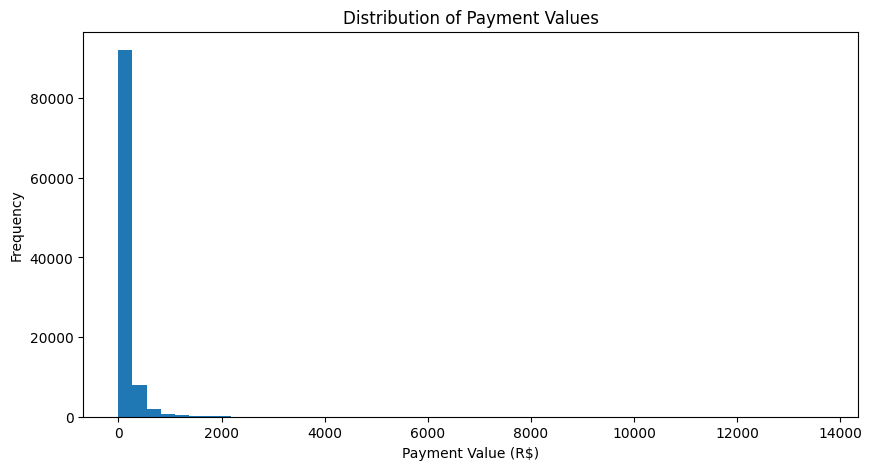

In [61]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(payments['payment_value'], bins=50)

plt.title('Distribution of Payment Values')
plt.xlabel('Payment Value (R$)')
plt.ylabel('Frequency')

plt.show()

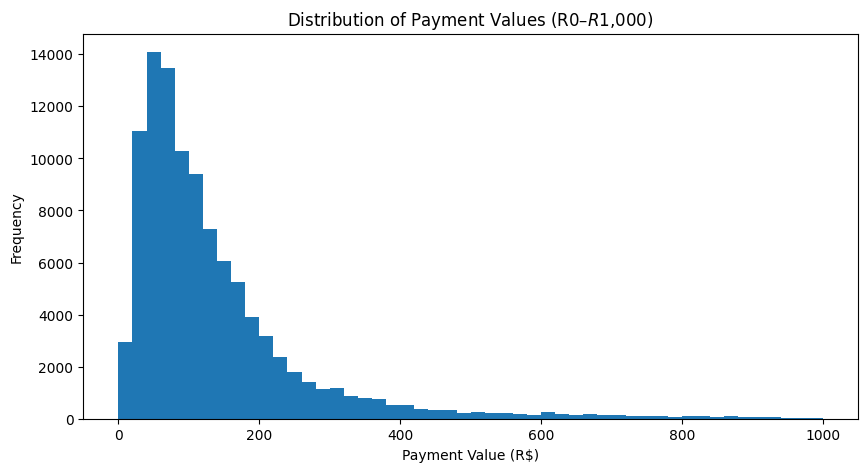

In [62]:
plt.figure(figsize=(10, 5))

plt.hist(
    payments['payment_value'],
    bins=50,
    range=(0, 1000)
)

plt.title('Distribution of Payment Values (R$0–R$1,000)')
plt.xlabel('Payment Value (R$)')
plt.ylabel('Frequency')

plt.show()

In [63]:
#zero payments 
zero_payments = payments[payments['payment_value'] == 0]

zero_payments

,order_id,payment_sequential,payment_type,payment_installments,payment_value
19922,8bcbe01d44d147f901cd3192671144db,4,voucher,1,0.0
36822,fa65dad1b0e818e3ccc5cb0e39231352,14,voucher,1,0.0
43744,6ccb433e00daae1283ccc956189c82ae,4,voucher,1,0.0
51280,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.0
57411,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.0
62674,45ed6e85398a87c253db47c2d9f48216,3,voucher,1,0.0
77885,fa65dad1b0e818e3ccc5cb0e39231352,13,voucher,1,0.0
94427,c8c528189310eaa44a745b8d9d26908b,1,not_defined,1,0.0
100766,b23878b3e8eb4d25a158f57d96331b18,4,voucher,1,0.0


In [64]:
#repeated order where payment value is 0
payments[
    payments['order_id'] == 'fa65dad1b0e818e3ccc5cb0e39231352'
]

,order_id,payment_sequential,payment_type,payment_installments,payment_value
4885,fa65dad1b0e818e3ccc5cb0e39231352,27,voucher,1,66.02
9985,fa65dad1b0e818e3ccc5cb0e39231352,4,voucher,1,29.16
14321,fa65dad1b0e818e3ccc5cb0e39231352,1,voucher,1,3.71
17274,fa65dad1b0e818e3ccc5cb0e39231352,9,voucher,1,1.08
19565,fa65dad1b0e818e3ccc5cb0e39231352,10,voucher,1,12.86
23074,fa65dad1b0e818e3ccc5cb0e39231352,2,voucher,1,8.51
24879,fa65dad1b0e818e3ccc5cb0e39231352,25,voucher,1,3.68
28330,fa65dad1b0e818e3ccc5cb0e39231352,5,voucher,1,0.66
29648,fa65dad1b0e818e3ccc5cb0e39231352,6,voucher,1,5.02
32519,fa65dad1b0e818e3ccc5cb0e39231352,11,voucher,1,4.03


In [65]:
payments[payments['payment_type'] == 'not_defined']

,order_id,payment_sequential,payment_type,payment_installments,payment_value
51280,4637ca194b6387e2d538dc89b124b0ee,1,not_defined,1,0.0
57411,00b1cb0320190ca0daa2c88b35206009,1,not_defined,1,0.0
94427,c8c528189310eaa44a745b8d9d26908b,1,not_defined,1,0.0


### Findings — Payment Value Analysis

- The dataset contains 103,886 payment records, with an average payment value of approximately R$154.10 and a median of R$100.00.
- The payment-value distribution is strongly right-skewed, with most records concentrated at lower values and a long tail toward higher values.
- A histogram restricted to R$0–R$1,000 made the distribution of typical payment values easier to examine.
- Nine records have zero payment value: six voucher records and three `not_defined` records.
- All nine zero-value records have one installment. The reason for these zero values is not established, so the records have been retained without modification.
- One order contains 29 voucher payment records, including two zero-value entries. This unusual case may warrant further investigation.

In [66]:
payments['payment_installments'].value_counts().sort_index()

payment_installments
0         2
1     52546
2     12413
3     10461
4      7098
5      5239
6      3920
7      1626
8      4268
9       644
10     5328
11       23
12      133
13       16
14       15
15       74
16        5
17        8
18       27
20       17
21        3
22        1
23        1
24       18
Name: count, dtype: int64

In [67]:
payments[payments['payment_installments'] == 0]

,order_id,payment_sequential,payment_type,payment_installments,payment_value
46982,744bade1fcf9ff3f31d860ace076d422,2,credit_card,0,58.69
79014,1a57108394169c0b47d8f876acc9ba2d,2,credit_card,0,129.94


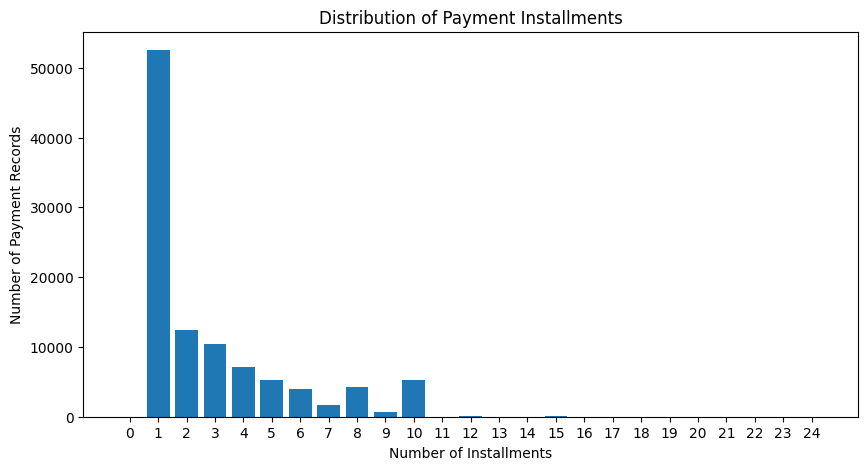

In [68]:
installment_counts = payments['payment_installments'].value_counts().sort_index()

plt.figure(figsize=(10, 5))

plt.bar(installment_counts.index, installment_counts.values)

plt.title('Distribution of Payment Installments')
plt.xlabel('Number of Installments')
plt.ylabel('Number of Payment Records')

plt.xticks(range(0, 25))
plt.show()

### Findings — Payment Installments

- One installment was the most common option, appearing in 52,546 payment records (approximately 50.6% of all records).
- The number of payment records generally decreased as installment counts increased, although some values, particularly 8 and 10 installments, showed noticeable increases relative to nearby counts.
- Higher installment counts were relatively uncommon.
- Two credit-card payment records had zero installments despite having positive payment values. These records were flagged for further investigation and retained without modification.
- The installment distribution is highly concentrated at one installment, with a smaller number of records using multiple installments.

In [69]:
payments.groupby('payment_type')['payment_value'].agg(
    ['count', 'sum', 'mean']
).sort_values('sum', ascending=False)

,count,sum,mean
payment_type,,,
credit_card,76795,12542084.19,163.319021
boleto,19784,2869361.27,145.034435
voucher,5775,379436.87,65.703354
debit_card,1529,217989.79,142.570170
not_defined,3,0.00,0.000000


In [70]:
payment_order_ids = set(payments['order_id'])
order_ids = set(df['order_id'])

print("Payment orders not found in orders dataset:", len(payment_order_ids - order_ids))
print("Orders without payment records:", len(order_ids - payment_order_ids))

Payment orders not found in orders dataset: 0
Orders without payment records: 1


In [71]:
orders_without_payment = df[
    ~df['order_id'].isin(payments['order_id'])
]

orders_without_payment

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
30710,bfbd0f9bdef84302105ad712db648a6c,86dc2ffce2dfff336de2f386a786e574,delivered,2016-09-15 12:16:38,2016-09-15 12:16:38,2016-11-07 17:11:53,2016-11-09 07:47:38,2016-10-04


### Findings — Payment Types

- Credit cards were the most frequently recorded payment method, with 76,795 records (approximately 73.9% of all payment records).
- Credit-card records had the highest combined payment value, approximately R$12.54 million.
- Boleto was the second most common method, with 19,784 records and a combined value of approximately R$2.87 million.
- Voucher payments had the lowest average payment value among defined payment types, at approximately R$65.70 per record.
- Debit-card payments averaged approximately R$142.57 per record, compared with R$145.03 for boleto.
- The three `not_defined` records had a combined payment value of zero.
- These totals and averages describe payment records, not necessarily unique orders. Orders with multiple payment records may contribute more than once.
- One order was present in the orders dataset but had no matching payment record. Its status was `delivered`. The reason for the missing payment record is unknown, so the order was retained without modification.

In [72]:
reviews = pd.read_csv("../data/olist_order_reviews_dataset.csv")

reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [73]:
reviews.shape

(99224, 7)

In [74]:
reviews.info()

<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   review_id                99224 non-null  str  
 1   order_id                 99224 non-null  str  
 2   review_score             99224 non-null  int64
 3   review_comment_title     11568 non-null  str  
 4   review_comment_message   40977 non-null  str  
 5   review_creation_date     99224 non-null  str  
 6   review_answer_timestamp  99224 non-null  str  
dtypes: int64(1), str(6)
memory usage: 5.3 MB


In [75]:
reviews.isnull().sum()

review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

In [76]:
reviews['review_creation_date'] = pd.to_datetime(
    reviews['review_creation_date']
)

reviews['review_answer_timestamp'] = pd.to_datetime(
    reviews['review_answer_timestamp']
)

In [77]:
reviews.info()

<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   review_id                99224 non-null  str           
 1   order_id                 99224 non-null  str           
 2   review_score             99224 non-null  int64         
 3   review_comment_title     11568 non-null  str           
 4   review_comment_message   40977 non-null  str           
 5   review_creation_date     99224 non-null  datetime64[us]
 6   review_answer_timestamp  99224 non-null  datetime64[us]
dtypes: datetime64[us](2), int64(1), str(4)
memory usage: 5.3 MB


In [78]:
reviews['review_score'].value_counts().sort_index()

review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

In [79]:
reviews['review_score'].value_counts(normalize=True).mul(100).round(2)

review_score
5    57.78
4    19.29
1    11.51
3     8.24
2     3.18
Name: proportion, dtype: float64

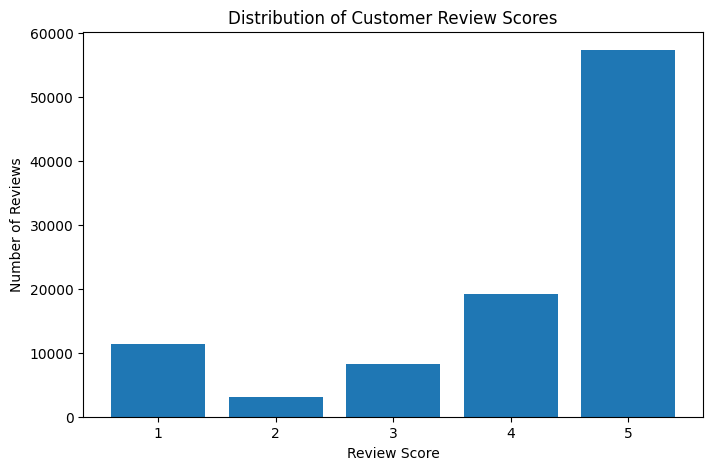

In [80]:
score_counts = reviews['review_score'].value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(score_counts.index, score_counts.values)

plt.title('Distribution of Customer Review Scores')
plt.xlabel('Review Score')
plt.ylabel('Number of Reviews')
plt.xticks([1, 2, 3, 4, 5])

plt.show()

In [81]:
reviews[['review_creation_date', 'review_answer_timestamp']].describe()

,review_creation_date,review_answer_timestamp
count,99224,99224
mean,2018-01-12 20:49:23.948238,2018-01-16 00:23:56.977939
min,2016-10-02 00:00:00,2016-10-07 18:32:28
25%,2017-09-23 00:00:00,2017-09-27 01:53:27.250000
50%,2018-02-02 00:00:00,2018-02-04 22:41:47.500000
75%,2018-05-16 00:00:00,2018-05-20 12:11:21.500000
max,2018-08-31 00:00:00,2018-10-29 12:27:35


In [82]:
print("Earliest review:", reviews['review_creation_date'].min())
print("Latest review:", reviews['review_creation_date'].max())

print(
    "Earliest response:",
    reviews['review_answer_timestamp'].min()
)
print(
    "Latest response:",
    reviews['review_answer_timestamp'].max()
)

Earliest review: 2016-10-02 00:00:00
Latest review: 2018-08-31 00:00:00
Earliest response: 2016-10-07 18:32:28
Latest response: 2018-10-29 12:27:35


In [83]:
monthly_reviews = (
    reviews.set_index('review_creation_date')
    .resample('MS')
    .size()
)

monthly_reviews

review_creation_date
2016-10-01     179
2016-11-01     101
2016-12-01      45
2017-01-01     239
2017-02-01    1413
2017-03-01    2481
2017-04-01    2055
2017-05-01    3710
2017-06-01    3440
2017-07-01    3503
2017-08-01    4503
2017-09-01    4199
2017-10-01    4424
2017-11-01    4786
2017-12-01    7982
2018-01-01    6179
2018-02-01    6101
2018-03-01    7803
2018-04-01    7287
2018-05-01    7458
2018-06-01    6715
2018-07-01    5634
2018-08-01    8987
Freq: MS, dtype: int64

### Findings — Review Dataset

- The dataset contains 99,224 review records, with review scores ranging from 1 to 5.
- Five-star reviews were the most common, accounting for 57.78% of all reviews. Scores of 4 or 5 represented approximately 77.07% of reviews.
- Review creation dates range from October 2, 2016, to August 31, 2018.
- Monthly review counts vary across the observed period, with August 2018 recording 8,987 reviews.
- No review-creation records are present for September or October 2018, despite a small number of purchases appearing in those months in the orders dataset.
- The reason for the difference in date coverage is not yet established. Further investigation across related datasets is needed.

In [84]:
products = pd.read_csv("../data/olist_products_dataset.csv")

products.head()

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [85]:
products.shape

(32951, 9)

In [86]:
products.info()

<class 'pandas.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  str    
 1   product_category_name       32341 non-null  str    
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), str(2)
memory usage: 2.3 MB


In [87]:
products.isnull().sum()

product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

In [88]:
products[
    products['product_category_name'].isnull()
]

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
105,a41e356c76fab66334f36de622ecbd3a,NaN,NaN,NaN,NaN,650.0,17.0,14.0,12.0
128,d8dee61c2034d6d075997acef1870e9b,NaN,NaN,NaN,NaN,300.0,16.0,7.0,20.0
145,56139431d72cd51f19eb9f7dae4d1617,NaN,NaN,NaN,NaN,200.0,20.0,20.0,20.0
154,46b48281eb6d663ced748f324108c733,NaN,NaN,NaN,NaN,18500.0,41.0,30.0,41.0
197,5fb61f482620cb672f5e586bb132eae9,NaN,NaN,NaN,NaN,300.0,35.0,7.0,12.0
...,...,...,...,...,...,...,...,...,...
32515,b0a0c5dd78e644373b199380612c350a,NaN,NaN,NaN,NaN,1800.0,30.0,20.0,70.0
32589,10dbe0fbaa2c505123c17fdc34a63c56,NaN,NaN,NaN,NaN,800.0,30.0,10.0,23.0
32616,bd2ada37b58ae94cc838b9c0569fecd8,NaN,NaN,NaN,NaN,200.0,21.0,8.0,16.0
32772,fa51e914046aab32764c41356b9d4ea4,NaN,NaN,NaN,NaN,1300.0,45.0,16.0,45.0


In [89]:
products[
    products['product_category_name'].isnull()
][
    ['product_category_name',
     'product_name_lenght',
     'product_description_lenght',
     'product_photos_qty']
].isnull().sum()

product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
dtype: int64

In [90]:
products[products['product_weight_g'].isnull()]

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
8578,09ff539a621711667c43eba6a3bd8466,bebes,60.0,865.0,3.0,NaN,NaN,NaN,NaN
18851,5eb564652db742ff8f28759cd8d2652a,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [91]:
print("Total rows:", len(products))
print("Unique product IDs:", products['product_id'].nunique())
print("Duplicate product IDs:", products['product_id'].duplicated().sum())

Total rows: 32951
Unique product IDs: 32951
Duplicate product IDs: 0


### Findings — Products Dataset

- The dataset contains 32,951 products across 9 columns.
- All 32,951 product IDs are unique, with no duplicate product IDs.
- A total of 610 products have missing values in `product_category_name`, `product_name_lenght`, `product_description_lenght`, and `product_photos_qty`. These missing values occur together.
- Two products have missing physical measurements (`product_weight_g`, `product_length_cm`, `product_height_cm`, and `product_width_cm`).
- One of these two products also has all four text-related fields missing, while the other retains its category and text-related metadata.
- No missing values have been filled, and no records have been removed during this initial investigation.

In [92]:
sellers = pd.read_csv("../data/olist_sellers_dataset.csv")

sellers.head()

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP


In [93]:
sellers.shape

(3095, 4)

In [94]:
sellers.info()

<class 'pandas.DataFrame'>
RangeIndex: 3095 entries, 0 to 3094
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   seller_id               3095 non-null   str  
 1   seller_zip_code_prefix  3095 non-null   int64
 2   seller_city             3095 non-null   str  
 3   seller_state            3095 non-null   str  
dtypes: int64(1), str(3)
memory usage: 96.8 KB


In [95]:
sellers.isnull().sum()

seller_id                 0
seller_zip_code_prefix    0
seller_city               0
seller_state              0
dtype: int64

In [96]:
print("Total rows:", len(sellers))
print("Unique seller IDs:", sellers['seller_id'].nunique())
print("Duplicate seller IDs:", sellers['seller_id'].duplicated().sum())

Total rows: 3095
Unique seller IDs: 3095
Duplicate seller IDs: 0


In [97]:
sellers['seller_state'].value_counts()

seller_state
SP    1849
PR     349
MG     244
SC     190
RJ     171
RS     129
GO      40
DF      30
ES      23
BA      19
CE      13
PE       9
PB       6
RN       5
MS       5
MT       4
RO       2
SE       2
AC       1
PI       1
MA       1
AM       1
PA       1
Name: count, dtype: int64

In [98]:
sellers['seller_city'].nunique()

611

### Findings — Sellers Dataset

- The dataset contains 3,095 seller records across 4 columns.
- All seller IDs are unique, with no duplicate IDs or missing values.
- Sellers are represented across 23 states and 611 distinct city names.
- São Paulo (SP) has the largest number of sellers, with 1,849 records (approximately 59.7%).
- Paraná (PR) follows with 349 sellers, and Minas Gerais (MG) has 244 sellers.
- The three states together account for approximately 78.9% of seller records.
- Geographic concentration will be explored further during marketplace analysis.

In [99]:
geolocation = pd.read_csv("../data/olist_geolocation_dataset.csv")

geolocation.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.545621,-46.639292,sao paulo,SP
1,1046,-23.546081,-46.644820,sao paulo,SP
2,1046,-23.546129,-46.642951,sao paulo,SP
3,1041,-23.544392,-46.639499,sao paulo,SP
4,1035,-23.541578,-46.641607,sao paulo,SP


In [100]:
geolocation.shape

(1000163, 5)

In [101]:
geolocation.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000163 entries, 0 to 1000162
Data columns (total 5 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   geolocation_zip_code_prefix  1000163 non-null  int64  
 1   geolocation_lat              1000163 non-null  float64
 2   geolocation_lng              1000163 non-null  float64
 3   geolocation_city             1000163 non-null  str    
 4   geolocation_state            1000163 non-null  str    
dtypes: float64(2), int64(1), str(2)
memory usage: 38.2 MB


In [102]:
geolocation.isnull().sum()

geolocation_zip_code_prefix    0
geolocation_lat                0
geolocation_lng                0
geolocation_city               0
geolocation_state              0
dtype: int64

In [103]:
print("Unique postal-code prefixes:",
      geolocation['geolocation_zip_code_prefix'].nunique())

print("Duplicate postal-code prefixes:",
      geolocation['geolocation_zip_code_prefix'].duplicated().sum())

print("Exact duplicate rows:",
      geolocation.duplicated().sum())

Unique postal-code prefixes: 19015
Duplicate postal-code prefixes: 981148
Exact duplicate rows: 261831


In [104]:
geolocation[geolocation.duplicated()].head(10)

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
15,1046,-23.546081,-46.644820,sao paulo,SP
44,1046,-23.546081,-46.644820,sao paulo,SP
65,1046,-23.546081,-46.644820,sao paulo,SP
66,1009,-23.546935,-46.636588,sao paulo,SP
67,1046,-23.546081,-46.644820,sao paulo,SP
72,1046,-23.545320,-46.644069,sao paulo,SP
79,1050,-23.549854,-46.643139,sao paulo,SP
80,1032,-23.540775,-46.635515,sao paulo,SP
82,1046,-23.546081,-46.644820,sao paulo,SP
86,1048,-23.547449,-46.640169,são paulo,SP


In [105]:
geolocation.duplicated().mean() * 100

np.float64(26.17883285024541)

In [106]:
prefix_counts = geolocation['geolocation_zip_code_prefix'].value_counts()

print("Prefixes with multiple records:", (prefix_counts > 1).sum())
print("Maximum records for one prefix:", prefix_counts.max())
print("Median records per prefix:", prefix_counts.median())

Prefixes with multiple records: 17972
Maximum records for one prefix: 1146
Median records per prefix: 29.0


### Findings — Geolocation Dataset

- The dataset contains 1,000,163 rows and 5 columns, with no missing values.
- It contains 19,015 unique postal-code prefixes.
- A total of 17,972 prefixes have multiple records, indicating that postal-code prefixes are not unique row identifiers in this dataset.
- The median number of records per prefix is 29, while the maximum is 1,146.
- There are 261,831 exact duplicate rows, representing approximately 26.18% of all records.
- City-name formatting varies in some records, including accent differences such as `sao paulo` and `são paulo`.
- The dataset may require aggregation or deduplication before being used for geographic joins. No records have been removed or modified during this initial investigation.

In [107]:
customers = pd.read_csv("../data/olist_customers_dataset.csv")

customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [108]:
customers.shape

(99441, 5)

In [109]:
customers.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  int64
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: int64(1), str(4)
memory usage: 3.8 MB


In [110]:
customers.isnull().sum()

customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

In [111]:
print("Total rows:", len(customers))
print("Unique customer IDs:", customers['customer_id'].nunique())
print("Unique customer identities:", customers['customer_unique_id'].nunique())

Total rows: 99441
Unique customer IDs: 99441
Unique customer identities: 96096


In [112]:
customer_identity_counts = (
    customers['customer_unique_id'].value_counts()
)

print("Customer identities with multiple records:",
      (customer_identity_counts > 1).sum())

print("Maximum records for one identity:",
      customer_identity_counts.max())

Customer identities with multiple records: 2997
Maximum records for one identity: 17


In [113]:
customers['customer_state'].value_counts()

customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
SC     3637
BA     3380
DF     2140
ES     2033
GO     2020
PE     1652
CE     1336
PA      975
MT      907
MA      747
MS      715
PB      536
PI      495
RN      485
AL      413
SE      350
TO      280
RO      253
AM      148
AC       81
AP       68
RR       46
Name: count, dtype: int64

In [114]:
customers['customer_city'].nunique()

4119

### Findings — Customers Dataset

- The dataset contains 99,441 customer records across 5 columns, with no missing values.
- All `customer_id` values are unique, while `customer_unique_id` has 96,096 unique values.
- A total of 2,997 customer identities appear in multiple records, with a maximum of 17 records for one identity.
- Customers are represented across 27 states and 4,119 distinct city names.
- São Paulo (SP) has the largest number of customer records, with 41,746 (approximately 42.0%).
- Rio de Janeiro (RJ) and Minas Gerais (MG) follow with 12,852 and 11,635 records, respectively.
- Customer records are geographically concentrated in a few states, particularly SP, RJ, and MG.
- Repeat purchasing must be confirmed by connecting customer identities to distinct orders.

In [115]:
category_translation = pd.read_csv(
    "../data/product_category_name_translation.csv"
)

category_translation.head()

,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


In [116]:
category_translation.shape

(71, 2)

In [117]:
category_translation.info()

<class 'pandas.DataFrame'>
RangeIndex: 71 entries, 0 to 70
Data columns (total 2 columns):
 #   Column                         Non-Null Count  Dtype
---  ------                         --------------  -----
 0   product_category_name          71 non-null     str  
 1   product_category_name_english  71 non-null     str  
dtypes: str(2)
memory usage: 1.2 KB


In [118]:
category_translation.isnull().sum() 

product_category_name            0
product_category_name_english    0
dtype: int64

In [119]:
print(
    "Unique Portuguese categories:",
    category_translation['product_category_name'].nunique()
)

print(
    "Unique English categories:",
    category_translation['product_category_name_english'].nunique()
)

print(
    "Duplicate rows:",
    category_translation.duplicated().sum()
)

Unique Portuguese categories: 71
Unique English categories: 71
Duplicate rows: 0


### Findings — Category Translation Dataset

- The dataset contains 71 rows and 2 columns.
- All 71 Portuguese product category names are unique.
- All 71 English category names are unique.
- No missing values or exact duplicate rows were found.
- The dataset provides English translations for Portuguese product categories and will support more readable category-level analysis and dashboard reporting.